In [1]:
import math 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(2025701040)

n = 15000
a, b = 3.5, 2.0
sigma = 1.0

x = np.random.uniform(-10, 10, n)
noise = np.random.normal(0, sigma, n)

y = a * x + b + noise

In [3]:
x, y

(array([-4.15745016, -6.15325694,  7.48834496, ...,  8.78788575,
         2.61666176,  9.69800987], shape=(15000,)),
 array([-12.63325931, -19.92100731,  28.0505852 , ...,  32.40510825,
         11.48216187,  34.84879624], shape=(15000,)))

In [4]:
y_org = a * x + b # this is the ideal line of we do not add the elipson noise to the actual line equation
y_org

array([-12.55107556, -19.53639928,  28.20920736, ...,  32.75760011,
        11.15831616,  35.94303454], shape=(15000,))

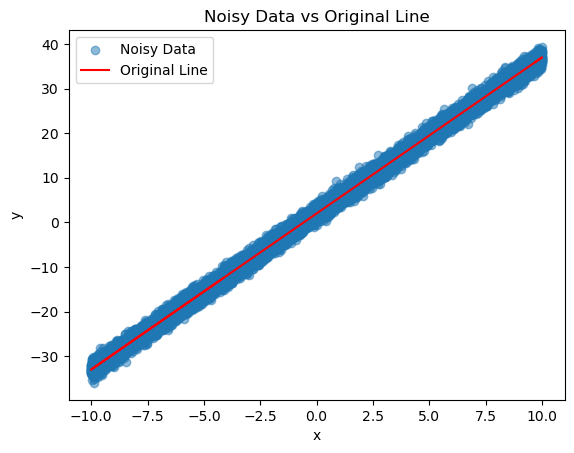

In [5]:
plt.scatter(x, y, alpha=0.5, label='Noisy Data')
plt.plot(x, y_org, color='red', label='Original Line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Noisy Data vs Original Line')
plt.legend()
plt.show()

In [6]:
epsilon = np.random.normal(0, 0.25, n)  #  small noise 0.25
x1 = x + epsilon
x2 = x - epsilon
epsilon2 = np.random.normal(0, 0.01, n)  # very small noise 0.01
x3 = x1 + epsilon2

In [7]:
X = np.column_stack([x, x1, x2, x3])
X.shape

(15000, 4)

In [8]:
X

array([[-4.15745016, -4.64096227, -3.67393805, -4.62474985],
       [-6.15325694, -5.75562622, -6.55088766, -5.75440091],
       [ 7.48834496,  7.36446616,  7.61222376,  7.35330052],
       ...,
       [ 8.78788575,  8.37011978,  9.20565171,  8.36830368],
       [ 2.61666176,  2.5101067 ,  2.72321682,  2.5104445 ],
       [ 9.69800987,  9.77642686,  9.61959288,  9.77540066]],
      shape=(15000, 4))

In [9]:
real_coef = np.array([2.0, -1.0, 1.0, 0.5])
noise = np.random.normal(0, 1, n)

y1 = X @ real_coef + noise
y1

array([ -8.74368231, -14.90573209,  20.44103293, ...,  21.86028104,
         7.85649784,  22.60977231], shape=(15000,))

In [10]:
XtX = X.T @ X

eigenvalues = np.linalg.eigvals(XtX)
condition_number = np.linalg.cond(XtX)
print("Eigenvalues of X^T X:", eigenvalues)
print("Condition number of X^T X:", condition_number)

Eigenvalues of X^T X: [2.01955454e+06 2.53904067e+03 1.93346783e-10 8.19969434e-01]
Condition number of X^T X: 8281294770722953.0


In [11]:
outlier_percent = 0.15 # 15% outliers
num_outliers = int(n * outlier_percent)
outlier_indices = np.random.choice(n, num_outliers, replace=False)
y[outlier_indices] += np.random.normal(0, 17, num_outliers)  # adding large noise to create outliers

In [12]:
y

array([-12.63325931, -33.18648716,  47.41375206, ...,  32.40510825,
        -1.00940375,  34.84879624], shape=(15000,))

### Part B - implementation from scratch

Implement each of the following. Show the key equations in your report.
B.1. Closed-form ordinary least squares (OLS). [1 mark]
B.2. Gradient descent for OLS (MSE objective). [1 mark]
B.3. Ridge regression—both closed-form and gradient descent. [1.5 marks]
B.4. Lasso regression via sub-gradient descent. [1.5 marks]
B.5. Weighted least squares (closed-form). [1 mark ]

In [ ]:
def closed_form_solution(X, y): #ols solution
    
    return np.linalg.pinv(X.T @ X) @ X.T @ y

def gradient_descent(X, y, learning_rate=0.01, max_iterations=1000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    loss = []
    
    for i in range(max_iterations):
        predictions = X @ w
        errors = predictions - y
        gradient = (2/n_samples) * (X.T @ errors)
        w -= learning_rate * gradient

        loss.append(np.mean(errors**2))
        if i % 10 == 0:
            print(f"Iteration {i}, Loss: {np.mean(errors**2)}, w: {w}")

        
    return w, loss

def ridge_regression(X, y, lambda_=1.0):
    n_features = X.shape[1]
    I = np.eye(n_features)
    return np.linalg.inv(X.T @ X + lambda_ * I) @ X.T @ y

def ridge_regression_gradient_descent(X, y, alpha=1.0, learning_rate=0.01, max_iterations=1000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    loss = []
    
    for i in range(max_iterations):
        predictions = X @ w
        errors = predictions - y
        gradient = (2/n_samples) * (X.T @ errors) + 2 * alpha * w
        w -= learning_rate * gradient
        loss.append(np.mean(errors**2) + alpha * np.sum(w**2))
        if i % 10 == 0:
            print(f"Iteration {i}, Loss: {np.mean(errors**2) + alpha * np.sum(w**2)}, w: {w}")
        
    return w, loss 

def lasso_regression_sub_gradient(X, y, alpha=1.0, learning_rate=0.01, max_iterations=1000):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    loss = []
    
    for i in range(max_iterations):
        predictions = X @ w
        errors = predictions - y
        gradient = (2/n_samples) * (X.T @ errors) + alpha * np.sign(w)
        w -= learning_rate * gradient

        loss.append(np.mean(errors**2) + alpha * np.sum(np.abs(w)))
        if i % 10 == 0:
            print(f"Iteration {i}, Loss: {np.mean(errors**2) + alpha * np.sum(np.abs(w))}, w: {w}")
        
    return w

def weighted_least_squares(X, y, weights):
    W = weights
    X_weighted = X * W[:, None]
    return np.linalg.pinv(X.T @ X_weighted) @ X.T @ (W * y)

In [18]:
#adding bias to x,

x_bias = np.column_stack([np.ones(n), x]) # clean dataset with bias

In [14]:
## clean dataset is x, y 

x, y

(array([-4.15745016, -6.15325694,  7.48834496, ...,  8.78788575,
         2.61666176,  9.69800987], shape=(15000,)),
 array([-12.63325931, -33.18648716,  47.41375206, ...,  32.40510825,
         -1.00940375,  34.84879624], shape=(15000,)))

In [28]:
x_bias

array([[ 1.        , -4.15745016],
       [ 1.        , -6.15325694],
       [ 1.        ,  7.48834496],
       ...,
       [ 1.        ,  8.78788575],
       [ 1.        ,  2.61666176],
       [ 1.        ,  9.69800987]], shape=(15000, 2))

### Part C — Gradient Descent Analysis [6 marks]


Using the clean dataset:
C.1. Train with at least three learning rates. Plot loss vs. iteration for each. Show one rate
that converges, one that oscillates, and one that diverges. [2.5 marks]
C.2. Relate convergence behaviour to the eigenvalues of XT X. Specifically, state and verify
the condition η < 2/λmax for convergence. [2 marks]
C.3. Written (5–8 sentences): Explain theoretically why the maximum eigenvalue of XT X
governs the convergence bound. [1.5 marks]

In [20]:
closed_form_solution(x_bias, y)

array([2.05865494, 3.49064034])

In [32]:
final_w, loss = gradient_descent(x_bias, y, learning_rate=0.01, max_iterations=1000)

Iteration 0, Loss: 458.84325374396377, w: [0.04031315 2.34875942]
Iteration 10, Loss: 47.59296769893402, w: [0.40916944 3.49000211]
Iteration 20, Loss: 46.65131273311078, w: [0.71090391 3.49013189]
Iteration 30, Loss: 46.02265523227692, w: [0.95744318 3.4902249 ]
Iteration 40, Loss: 45.60295767715042, w: [1.1588839  3.49030089]
Iteration 50, Loss: 45.32276371216074, w: [1.3234758  3.49036299]
Iteration 60, Loss: 45.135703632687594, w: [1.45795949 3.49041372]
Iteration 70, Loss: 45.010820595560844, w: [1.56784255 3.49045518]
Iteration 80, Loss: 44.92744752629922, w: [1.65762511 3.49048905]
Iteration 90, Loss: 44.871786895055514, w: [1.73098406 3.49051672]
Iteration 100, Loss: 44.8346273434415, w: [1.79092372 3.49053934]
Iteration 110, Loss: 44.80981928350216, w: [1.83989883 3.49055781]
Iteration 120, Loss: 44.793257193508545, w: [1.87991511 3.49057291]
Iteration 130, Loss: 44.782200189227375, w: [1.91261134 3.49058524]
Iteration 140, Loss: 44.774818431024116, w: [1.93932658 3.49059532]


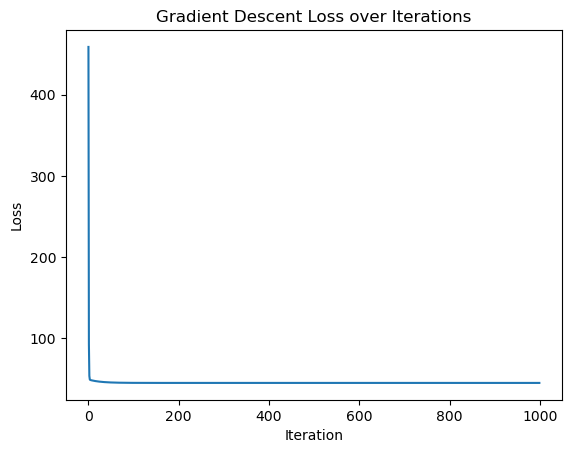

In [33]:
plt.plot(loss)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Gradient Descent Loss over Iterations')
plt.show()

In [34]:
final_w, loss = gradient_descent(x_bias, y, learning_rate=0.1, max_iterations=1000) # higher learning rate causing ultimate overflows

Iteration 0, Loss: 458.84325374396377, w: [ 0.4031315  23.48759415]
Iteration 10, Loss: 5.9702565473002e+17, w: [-2.87942443e+05  7.63249942e+08]
Iteration 20, Loss: 8.697047825115912e+32, w: [-1.09900067e+13  2.91310548e+16]
Iteration 30, Loss: 1.266924465859977e+48, w: [-4.19456944e+20  1.11184857e+24]
Iteration 40, Loss: 1.845566029382156e+63, w: [-1.60094651e+28  4.24360620e+31]
Iteration 50, Loss: 2.688490167010367e+78, w: [-6.11035233e+35  1.61966243e+39]
Iteration 60, Loss: 3.916402481969823e+93, w: [-2.33214573e+43  6.18178562e+46]
Iteration 70, Loss: 5.705138366875889e+108, w: [-8.90112946e+50  2.35940976e+54]
Iteration 80, Loss: 8.310842395551847e+123, w: [-3.39730509e+58  9.00518843e+61]
Iteration 90, Loss: 1.2106647881622614e+139, w: [-1.29665364e+66  3.43702141e+69]
Iteration 100, Loss: 1.7636109067360688e+154, w: [-4.94895397e+73  1.31181221e+77]
Iteration 110, Loss: 2.5691037360389024e+169, w: [-1.88887338e+81  5.00680989e+84]
Iteration 120, Loss: 3.7424887662688924e+184

/home/vanshnawander/miniconda3/lib/python3.13/site-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_9701/2020345069.py:16: RuntimeWarning: overflow encountered in square
  loss.append(np.mean(errors**2))
/tmp/ipykernel_9701/2020345069.py:18: RuntimeWarning: overflow encountered in square
  print(f"Iteration {i}, Loss: {np.mean(errors**2)}, w: {w}")
/tmp/ipykernel_9701/2020345069.py:13: RuntimeWarning: invalid value encountered in matmul
  gradient = (2/n_samples) * (X.T @ errors)
/tmp/ipykernel_9701/2020345069.py:14: RuntimeWarning: invalid value encountered in subtract
  w -= learning_rate * gradient


Iteration 370, Loss: inf, w: [-2.51262738e+278  6.66018577e+281]
Iteration 380, Loss: inf, w: [-9.58997601e+285  2.54200134e+289]
Iteration 390, Loss: inf, w: [-3.66021800e+293  9.70208796e+296]
Iteration 400, Loss: inf, w: [nan nan]
Iteration 410, Loss: nan, w: [nan nan]
Iteration 420, Loss: nan, w: [nan nan]
Iteration 430, Loss: nan, w: [nan nan]
Iteration 440, Loss: nan, w: [nan nan]
Iteration 450, Loss: nan, w: [nan nan]
Iteration 460, Loss: nan, w: [nan nan]
Iteration 470, Loss: nan, w: [nan nan]
Iteration 480, Loss: nan, w: [nan nan]
Iteration 490, Loss: nan, w: [nan nan]
Iteration 500, Loss: nan, w: [nan nan]
Iteration 510, Loss: nan, w: [nan nan]
Iteration 520, Loss: nan, w: [nan nan]
Iteration 530, Loss: nan, w: [nan nan]
Iteration 540, Loss: nan, w: [nan nan]
Iteration 550, Loss: nan, w: [nan nan]
Iteration 560, Loss: nan, w: [nan nan]
Iteration 570, Loss: nan, w: [nan nan]
Iteration 580, Loss: nan, w: [nan nan]
Iteration 590, Loss: nan, w: [nan nan]
Iteration 600, Loss: nan,

In [ ]:
gradient_descent(x_bias, y, learning_rate=0.001, max_iterations=1000) 

Iteration 0, Loss: 458.84325374396377, w: [0.00403132 0.23487594]
Iteration 10, Loss: 150.56386485248677, w: [0.04416388 1.86821764]
Iteration 20, Loss: 73.92669409757038, w: [0.08379797 2.68196946]
Iteration 30, Loss: 54.79044881801595, w: [0.12279444 3.08739465]
Iteration 40, Loss: 49.9310708132563, w: [0.16109169 3.28938796]
Iteration 50, Loss: 48.61967514830198, w: [0.19866657 3.39002969]
Iteration 60, Loss: 48.19306021278846, w: [0.23551498 3.44017707]
Iteration 70, Loss: 47.99002655764068, w: [0.27164214 3.46516762]
Iteration 80, Loss: 47.84630110146366, w: [0.30705777 3.47762469]
Iteration 90, Loss: 47.720959726548756, w: [0.3417737  3.48383734]
Iteration 100, Loss: 47.60370082270393, w: [0.37580265 3.48693885]
Iteration 110, Loss: 47.49182928186376, w: [0.40915768 3.48849024]
Iteration 120, Loss: 47.3845434388711, w: [0.44185187 3.48926922]
Iteration 130, Loss: 47.28151681156521, w: [0.47389817 3.48966325]
Iteration 140, Loss: 47.18254586789603, w: [0.50530935 3.48986539]
Itera

array([1.78042328, 3.49053538])

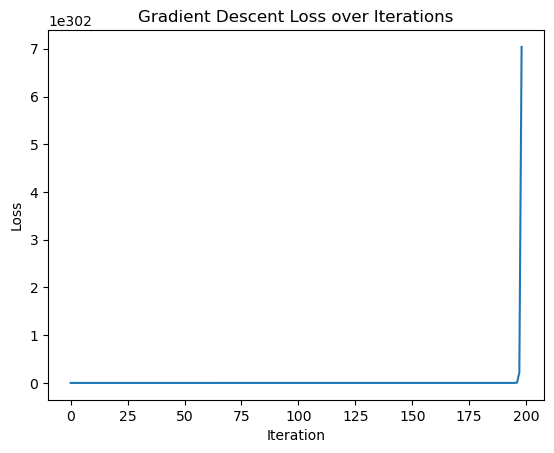

In [35]:
plt.plot(loss)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Gradient Descent Loss over Iterations')
plt.show()

In [42]:
final_w, loss = gradient_descent(x_bias, y, learning_rate=0.02, max_iterations=1000) 

Iteration 0, Loss: 458.84325374396377, w: [0.0806263  4.69751883]
Iteration 10, Loss: 46.63562086877564, w: [0.74389728 3.49017406]
Iteration 20, Loss: 45.58902769078599, w: [1.18455946 3.49031058]
Iteration 30, Loss: 45.12642927717367, w: [1.47752661 3.4904211 ]
Iteration 40, Loss: 44.92195886062622, w: [1.67230112 3.49049458]
Iteration 50, Loss: 44.83158208886728, w: [1.80179381 3.49054344]
Iteration 60, Loss: 44.79163518108723, w: [1.88788495 3.49057592]
Iteration 70, Loss: 44.77397848224604, w: [1.94512126 3.49059751]
Iteration 80, Loss: 44.76617414816128, w: [1.9831739  3.49061186]
Iteration 90, Loss: 44.76272460014245, w: [2.00847259 3.49062141]


Iteration 100, Loss: 44.76119988561782, w: [2.02529201 3.49062775]
Iteration 110, Loss: 44.76052595547712, w: [2.03647413 3.49063197]
Iteration 120, Loss: 44.760228075561116, w: [2.04390839 3.49063478]
Iteration 130, Loss: 44.76009641140336, w: [2.04885093 3.49063664]
Iteration 140, Loss: 44.760038215299815, w: [2.05213691 3.49063788]
Iteration 150, Loss: 44.76001249238079, w: [2.05432153 3.49063871]
Iteration 160, Loss: 44.760001122743944, w: [2.05577394 3.49063925]
Iteration 170, Loss: 44.75999609731732, w: [2.05673956 3.49063962]
Iteration 180, Loss: 44.759993876057926, w: [2.05738153 3.49063986]
Iteration 190, Loss: 44.759992894252065, w: [2.05780834 3.49064002]
Iteration 200, Loss: 44.7599924602898, w: [2.05809209 3.49064013]
Iteration 210, Loss: 44.75999226847668, w: [2.05828074 3.4906402 ]
Iteration 220, Loss: 44.75999218369449, w: [2.05840616 3.49064025]
Iteration 230, Loss: 44.759992146220405, w: [2.05848954 3.49064028]
Iteration 240, Loss: 44.7599921296567, w: [2.05854498 3.4

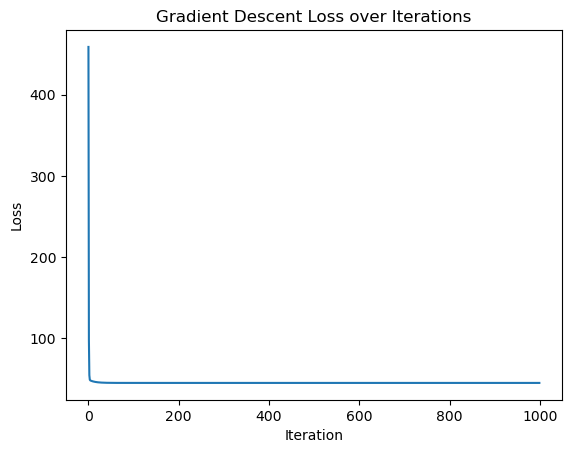

In [37]:
plt.plot(loss)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Gradient Descent Loss over Iterations')
plt.show()

In [44]:
eigenvalues = np.linalg.eigvals(x_bias.T @ x_bias)
lambda_max = np.max(eigenvalues)
print("Maximum eigenvalue of X^T X:", lambda_max)
print(eigenvalues)

Maximum eigenvalue of X^T X: 504764.1716434005
[ 14999.93029395 504764.1716434 ]


In [40]:
2/lambda_max

np.float64(3.962246356528123e-06)